<font color ='Navy'><center> __BruFace__ </center></font>
<br> MA1 Mechanical Engineering <br>  __Mechanical vibrations__ <br>
**Academic Year 2026-2027**
***
<font color='Navy'><h1><center>Project: 4 DOFs Model of a Car Under Road Excitation </center></h1></font>
- Arnaud Deraemaeker ([Arnaud.Deraemaeker@ulb.be](mailto:Arnaud.Deraemaeker@ulb.be))  
- Wout Weijtjens ([Wout.Weijtjens@vub.be](mailto:Wout.Weijtjens@vub.be))
***


# **1. Model and equations**

Consider the 4 DOFs model of a car represented below. $X_{01}$ and $X_{02}$ represent the motion imposed on each wheel due to the road profile. The car body is assumed to be rigid and the motion is restricted to a plane, resulting in 2 DOFs (translation, rotation), while each wheel is also assumed to be a rigid body and can only move vertically. $K_0, B_0$ are the mechanical parameters of the car suspension, while $k, b$ are the stiffness and damping of the tires.

---

## **Model Diagram**
![4 DOFs Model of a Car](https://github.com/OWI-Lab/MV2627_Exercises/blob/main/Project2627/images/car.png?raw=1)

---

1. Based on the equations of motion derived for each body separately, derive the full set of equations of motion for the car in a matrix form, and determine the mass, damping, and stiffness matrices. Use absolute displacements in the equations. Give the expression of the force vector.

2. Assume harmonic excitation and write the equations of motion in the frequency domain.
What assumption could you make to have the force vector independent of the frequency?
Give the expression of the force vector in this simplified case.

***Small Angle Assumption*** : It is assumed that the rotation angles of the car body are small enough such that $sin⁡(q3)≈q3$. This linearizes the rotational dynamics, allowing for the use of linear equations of motion.


1. 
$$
m\ddot x_1 + b\dot x_1 + k x_1
  + B_0 (\dot x_1-\dot x_3+\frac{L}{2}\dot q_3)
  + K_0 (x_1-x_3+\frac{L}{2}q_3) = b \dot x_{01} + k x_{01} \\
m\ddot x_2 + b \dot x_2 + k x_2
  + B_0 (\dot x_2-\dot x_3-\frac{L}{2}\dot q_3)
  + K_0 (x_2-x_3-\frac{L}{2}q_3) = b \dot x_{02} + k x_{02} \\
M_0\ddot x_3 + B_0(2\dot x_3-\dot x_1-\dot x_2)
  + K_0(2x_3-x_1-x_2) = 0 \\
I_G\ddot q_3 + B_0\frac{L}{2} (L\dot q_3+\dot x_1-\dot x_2)
  + K_0\frac{L}{2}(Lq_3+x_1-x_2) = 0
$$


$ M \ddot x + C \dot x + K x = f$


$$
\begin{bmatrix} m&0&0&0\\ 0&m&0&0\\ 0&0&M_0&0\\ 0&0&0&I_G \end{bmatrix}
\begin{bmatrix} \ddot x_1\\ \ddot x_2\\ \ddot x_3\\ \ddot q_3 \end{bmatrix}
+
\begin{bmatrix}
b+B_0 & 0 & -B_0 & \frac{L}{2}B_0\\
0 & b+B_0 & -B_0 & -\frac{L}{2}B_0\\
-B_0 & -B_0 & 2B_0 & 0\\
\frac{L}{2}B_0 & -\frac{L}{2}B_0 & 0 & \frac{L^2}{2}B_0
\end{bmatrix}
\begin{bmatrix} \dot x_1\\ \dot x_2\\ \dot x_3\\ \dot q_3 \end{bmatrix}
+
\begin{bmatrix}
k+K_0 & 0 & -K_0 & \frac{L}{2}K_0\\
0 & k+K_0 & -K_0 & -\frac{L}{2}K_0\\
-K_0 & -K_0 & 2K_0 & 0\\
\frac{L}{2}K_0 & -\frac{L}{2}K_0 & 0 & \frac{L^2}{2}K_0
\end{bmatrix}
\begin{bmatrix} x_1\\ x_2\\ x_3\\ q_3 \end{bmatrix}
=
\begin{bmatrix} b\dot x_{01}+kx_{01}\\ b\dot x_{02}+kx_{02}\\ 0\\ 0 \end{bmatrix}
$$

2. Lets assume harmonic excitation: $x(t) = X e^{i\omega t} = \begin{bmatrix} X_1 \\ X_{2}\\ X_3 \\ Q3 \end{bmatrix} e^{i\omega t} $ ,  $x_{01}(t) = X_{01}e^{i \omega t}$ and $x_{02}(t) = X_{02}e^{i \omega t}$
That gives us:
$$(K + i \omega C - \omega^2 M) X = 
\begin{bmatrix} (i \omega b + k) X_{01} \\ (i \omega b + k) X_{02}\\ 0\\ 0 \end{bmatrix} $$
So as we see the only way to have the force vector independent of the frequency is to have no damping (b=0).
$$F = k \begin{bmatrix} X_{01} \\ X_{02}\\ 0\\ 0 \end{bmatrix}$$



In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

from scipy import linalg
from scipy import signal

# Only if the session is opend in google colab link
if "google.colab" in sys.modules:
    repo = "/content/MV2627_Exercises"
    if not os.path.exists(repo):
        !git clone -q https://github.com/OWI-Lab/MV2627_Exercises.git {repo}
    %cd /content/MV2627_Exercises/Project2627
    !pip install -q uv

# **2. Frequency Domain Computations**

Consider the following values of the parameters:
- $M_0 = 1500 \, \text{kg}$
- $K_0 = 65 000 \, \text{N/m}$
- $B_0 = 65 \, \text{N/(m/s)}$
- $m = 10 \, \text{kg}$
- $k = 100 000 \, \text{N/m}$
- $b = 10 \, \text{N/(m/s)}$
- $L = 4 \, \text{m}$
- $I_G = 5700 \, \text{kg} \cdot \text{m}^2$

Answer the following questions providing your answer to each question in the cell below it and in a separate code cell.

## **2.1 Computation of transmissibilities**


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Compute the mode shapes and the natural frequencies of the car. Give a physical interpretation of each of the mode shapes (what kind of motion of the car is related to each mode shape)

</div>

In [2]:
#Parameters of the systems
M0 = 1500
K0 = 65000
B0 = 65

m = 10
k = 100000
b = 10
L = 4
IG = 5700


M = np.array([
    [m, 0,  0,  0],
    [0, m,  0,  0],
    [0, 0,  M0, 0],
    [0, 0,  0,  IG]
])


C = np.array([
    [b + B0,    0,         -B0,   L/2 * B0],
    [0,         b + B0,    -B0,  -L/2 * B0],
    [-B0,       -B0,       2*B0,  0],
    [L/2 * B0, -L/2 * B0,  0,     L**2/2 * B0]
])


K = np.array([
    [k + K0,    0,         -K0,   L/2 * K0],
    [0,         k + K0,    -K0,  -L/2 * K0],
    [-K0,       -K0,       2*K0,  0],
    [L/2 * K0, -L/2 * K0,  0,     L**2/2 * K0]
])



Calculation of mode shapes and natural frequency

In [3]:
def calc_eigenvalues_eigenvectors(M:np.array,K:np.array):
    """
    A function that computes the eigenvalues and eigenvectors
    based on the system parameter by reworking the equations of motion to a generalized eigenvalue problem

    Arguments:
    M,K -- system matrices of the MDOF system

    Returns:
    lamb -- The eigenvalues of the conservative eigenvalue problem
    psi -- The eigenvectors of the conservative eigenvalue problem
  
    
    """   
    
    lamb, psi = linalg.eig(K,M)
    # sort the eigenvalues and eigenvectors from smallest to largest
    idx = np.abs(lamb).argsort()[::1]
    lamb = lamb[idx]
    psi = psi[:,idx]

    return lamb, psi

    

In [4]:
lamb, psi = calc_eigenvalues_eigenvectors(M,K)
freq_nat = np.sqrt(lamb)/(2*np.pi)
print(freq_nat)
print(psi)

[ 1.15226913+0.j  1.18213852+0.j 20.46502995+0.j 20.46614925+0.j]
[[-3.44973003e-01 -5.27032217e-01 -7.07101873e-01  7.07105421e-01]
 [-3.44973003e-01  5.27032217e-01 -7.07101873e-01 -7.07105421e-01]
 [-8.72918813e-01 -1.18811614e-14  3.72590673e-03 -2.14910555e-15]
 [ 3.83357161e-15  6.66688896e-01  1.45577055e-15  1.96134164e-03]]


Interpretation:
Mode 1: Rigid mouvement of the 3 masses synchronised (the entirer car moves up and down)
Mode 2: Mass 1 and two moves in phase opposition so the mass 3 rotate (it rotate naturaly in the mouvement of the mass 1 and 2) 
Mode 3: Mass 1 and 2 (synchronised) moves in phase oppostion of the mass 3
Mode 4: Similar to the mode 2 but the mass 3 rotate in opposition of mass 1 and 2

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. Assuming $X_{01} = X_{02}$ , compute and represent the transmissibility $X_{3}/X_{01}$ using the full model with the coupled equations (no simplification of the force vector). Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong. Which kind of imposed motion is applied when X01 = X02? Can you make a link with the peaks present in the transmissibility curve?

</div>

If we express the equations of the harmonics response of our system explicitly (with $X_{01}=X_{02}$) we have:
$$
\begin{bmatrix}
k+K_0-m\omega^2+i\omega(b+B_0) & 0 & -(K_0+i\omega B_0) & \frac{L}{2}(K_0+i\omega B_0)\\[4pt]
0 & k+K_0-m\omega^2+i\omega(b+B_0) & -(K_0+i\omega B_0) & -\frac{L}{2}(K_0+i\omega B_0)\\[4pt]
-(K_0+i\omega B_0) & -(K_0+i\omega B_0) & 2(K_0+i\omega B_0)-M_0\omega^2 & 0\\[4pt]
\frac{L}{2}(K_0+i\omega B_0) & -\frac{L}{2}(K_0+i\omega B_0) & 0 & \frac{L^2}{2}(K_0+i\omega B_0)-I_G\omega^2
\end{bmatrix}
 \begin{bmatrix} X_1 \\ X_{2}\\ X_3 \\ Q3 \end{bmatrix} =
 \begin{bmatrix} (i \omega b + k) X_{01} \\ (i \omega b + k) X_{01}\\ 0\\ 0 \end{bmatrix}
 $$

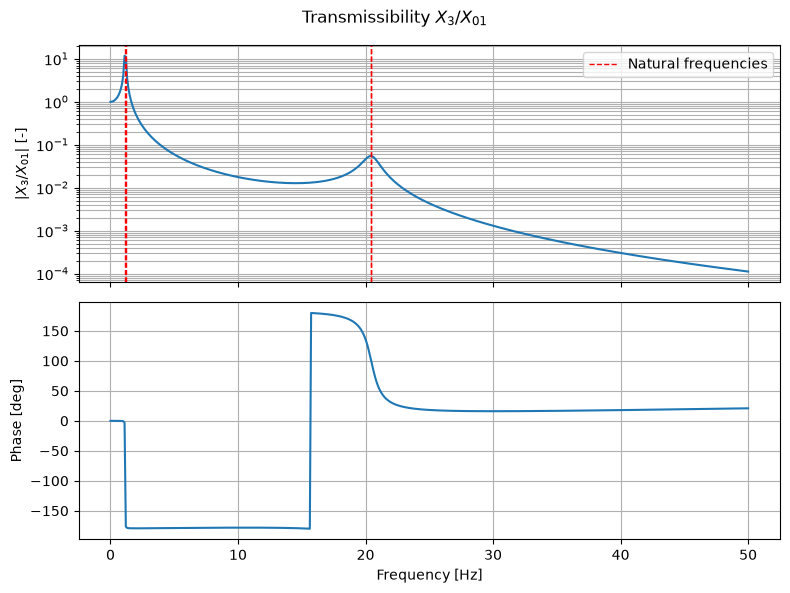

In [5]:
f = np.linspace(0, 50, 500)      
w = 2*np.pi*f                    

X3 = np.zeros(len(f), dtype=complex)

for n, wn in enumerate(w):
    D = K + 1j*wn*C - wn**2*M                     
    F = np.array([1, 1, 0, 0])*(1j*wn*b + k)      # X01 = X02 = 1
    X = np.linalg.solve(D, F)
    X3[n] = X[2]                            


# --- Plot de la transmissibilité X3/X01 ---
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

ax[0].semilogy(f, np.abs(X3))
ax[0].set_ylabel(r"$|X_3/X_{01}|$ [-]")
ax[0].grid(True, which="both")
for i, fn in enumerate(freq_nat):
    ax[0].axvline(abs(fn), color="r", linestyle="--", linewidth=1,
                  label="Natural frequencies" if i == 0 else None)
ax[0].legend()

ax[1].plot(f, np.angle(X3, deg=True))
ax[1].set_ylabel("Phase [deg]")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].grid(True)

fig.suptitle(r"Transmissibility $X_3/X_{01}$")
plt.tight_layout()
plt.show()


Analyse:
We imposed that the ground moves the two wheels perfectly synchronised and with the same amplitude. With that we and the graph we can understand that the two peaks correspond respectively to mode shape 1 and 3. So the frequencies 1.152 and 20.465 Hz

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

3. Now, use the simplified force vector derived in point 1.2, compute and represent the transmissibility $X_{3}/X_{01}$ using the full model with the coupled equations. Compare with the previous case by plotting the two curves on the same graph and comment. Is the simplification used for the force vector valid in your opinion?

</div>


In [6]:
X3simp = np.zeros(len(f), dtype=complex)

Fsimp = np.array([1, 1, 0, 0])*k     # X01 = X02 = 1 and b=0
for n, wn in enumerate(w):
    D = K + 1j*wn*C - wn**2*M                 
    Xsimp = np.linalg.solve(D, Fsimp)
    X3simp[n] = Xsimp[2]  

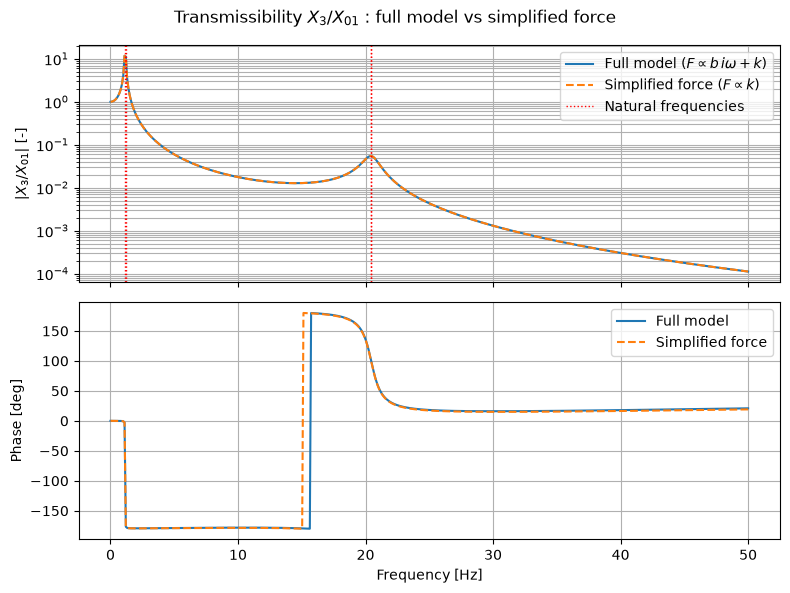

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# --- Amplitude ---
ax[0].semilogy(f, np.abs(X3), label=r"Full model ($F \propto b\,i\omega + k$)")
ax[0].semilogy(f, np.abs(X3simp), "--", label=r"Simplified force ($F \propto k$)")
ax[0].set_ylabel(r"$|X_3/X_{01}|$ [-]")
ax[0].grid(True, which="both")

for i, fn in enumerate(freq_nat):
    ax[0].axvline(abs(fn), color="r", linestyle=":", linewidth=1,
                  label="Natural frequencies" if i == 0 else None)
ax[0].legend()

# --- Phase ---
ax[1].plot(f, np.angle(X3, deg=True), label="Full model")
ax[1].plot(f, np.angle(X3simp, deg=True), "--", label="Simplified force")
ax[1].set_ylabel("Phase [deg]")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].grid(True)
ax[1].legend()

fig.suptitle(r"Transmissibility $X_3/X_{01}$ : full model vs simplified force")
plt.tight_layout()
plt.show()

The two curves of amplitude are perfectly superposed. So that we can conclude that our approximation is good enough.
We can notice that on the phase graphe there is a deviation around the 15 Hz frequency.
We can plot the relative error to see if it is constant in frequency and range of amplitude


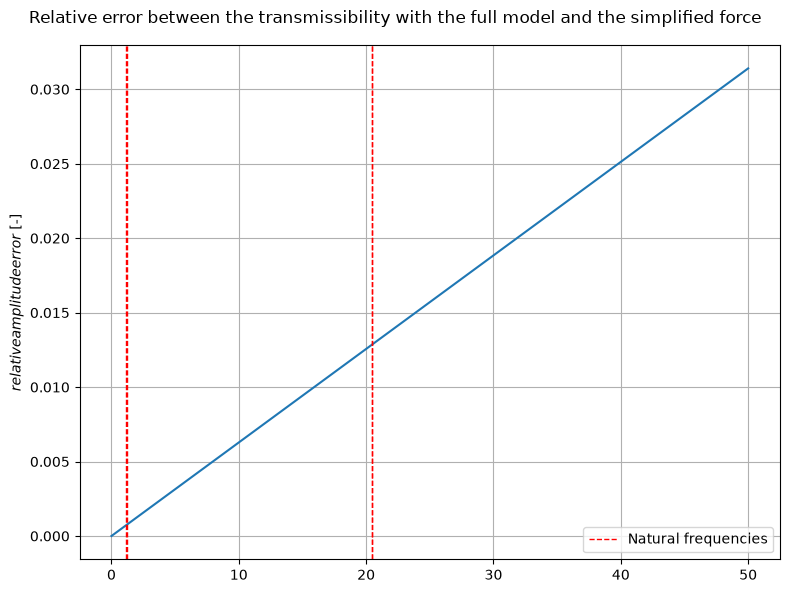

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharex=True)

ax.plot(f, np.abs((X3-X3simp)/X3))
ax.set_ylabel(r"$relative amplitude error$ [-]")
ax.grid(True, which="both")
for i, fn in enumerate(freq_nat):
    ax.axvline(abs(fn), color="r", linestyle="--", linewidth=1,
                  label="Natural frequencies" if i == 0 else None)
ax.legend()


fig.suptitle(r"Relative error between the transmissibility with the full model and the simplified force")
plt.tight_layout()
plt.show()

The relative error is proportional to the frequency. We can conclude that this simplification is valid since we work at low frequency

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

4. Assuming $X_{01} = −X_{02}$ , compute and represent the transmissibility $q_{3}/X_{01}$ using the full model with the coupled equations (no simplification of the force vector). Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong. Which kind of imposed motion is applied when $X_{01} = −X_{02}$ ? Can you make a link with the peaks present in the transmissibility curve?

</div>


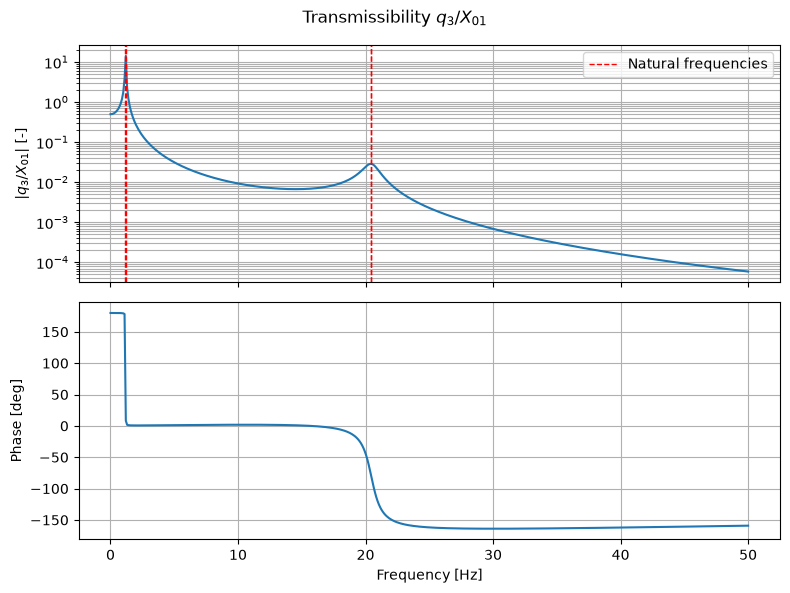

In [9]:
q3 = np.zeros(len(f), dtype=complex)

for n, wn in enumerate(w):
    D = K + 1j*wn*C - wn**2*M                     
    F = np.array([1, -1, 0, 0])*(1j*wn*b + k)      # X01 = - X02
    X = np.linalg.solve(D, F)
    q3[n] = X[3]                            


# --- Plot de la transmissibilité X3/X01 ---
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

ax[0].semilogy(f, np.abs(q3))
ax[0].set_ylabel(r"$|q_3/X_{01}|$ [-]")
ax[0].grid(True, which="both")
for i, fn in enumerate(freq_nat):
    ax[0].axvline(abs(fn), color="r", linestyle="--", linewidth=1,
                  label="Natural frequencies" if i == 0 else None)
ax[0].legend()

ax[1].plot(f, np.angle(q3, deg=True))
ax[1].set_ylabel("Phase [deg]")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].grid(True)

fig.suptitle(r"Transmissibility $q_3/X_{01}$")
plt.tight_layout()
plt.show()

Analyse:
We imposed that the ground moves the two wheels in phase opposition and with the same amplitude. With that  and the graph we can understand that the two peaks correspond respectively to mode shape 2 and 4. So the frequencies 1.182 and 20.466 Hz

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

5. Use the simplified force vector derived in point 1.2, compute and represent the transmissibility $q_{3}/X_{01}$ using the full model with the coupled equations. Compare with the previous case by plotting the two curves on the same graph and comment. Is the simplification used for the force vector valid in your opinion?

</div>


In [10]:
q3simp = np.zeros(len(f), dtype=complex)
Fsimp2 = np.array([1, -1, 0, 0])*k     # X01 = X02 = 1 and b=0
for n, wn in enumerate(w):
    D = K + 1j*wn*C - wn**2*M                 
    qsimp = np.linalg.solve(D, Fsimp2)
    q3simp[n] = qsimp[3]  

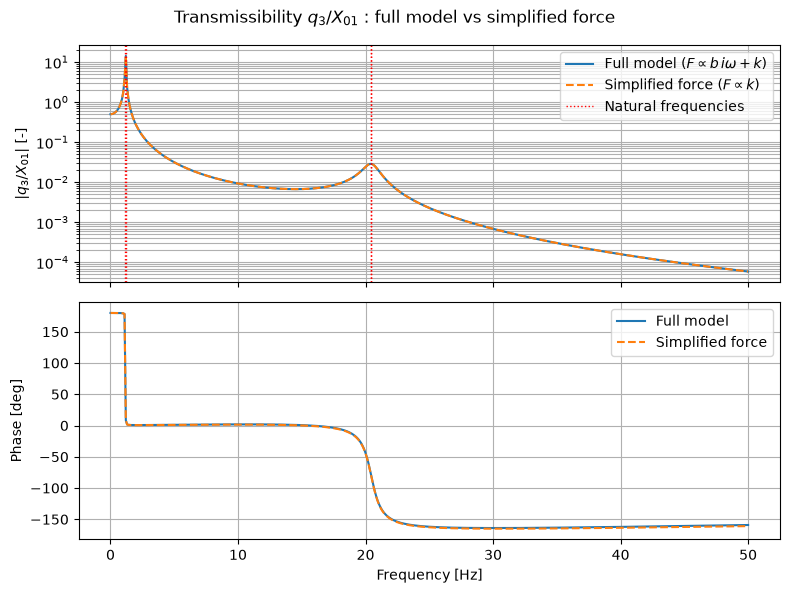

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# --- Amplitude ---
ax[0].semilogy(f, np.abs(q3), label=r"Full model ($F \propto b\,i\omega + k$)")
ax[0].semilogy(f, np.abs(q3simp), "--", label=r"Simplified force ($F \propto k$)")
ax[0].set_ylabel(r"$|q_3/X_{01}|$ [-]")
ax[0].grid(True, which="both")

for i, fn in enumerate(freq_nat):
    ax[0].axvline(abs(fn), color="r", linestyle=":", linewidth=1,
                  label="Natural frequencies" if i == 0 else None)
ax[0].legend()

# --- Phase ---
ax[1].plot(f, np.angle(q3, deg=True), label="Full model")
ax[1].plot(f, np.angle(q3simp, deg=True), "--", label="Simplified force")
ax[1].set_ylabel("Phase [deg]")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].grid(True)
ax[1].legend()

fig.suptitle(r"Transmissibility $q_3/X_{01}$ : full model vs simplified force")
plt.tight_layout()
plt.show()

The two curves of amplitude are perfectly superposed. So that we can conclude that our approximation is good enough.
We can plot the relative error to see if it is constant in frequency and range of amplitude

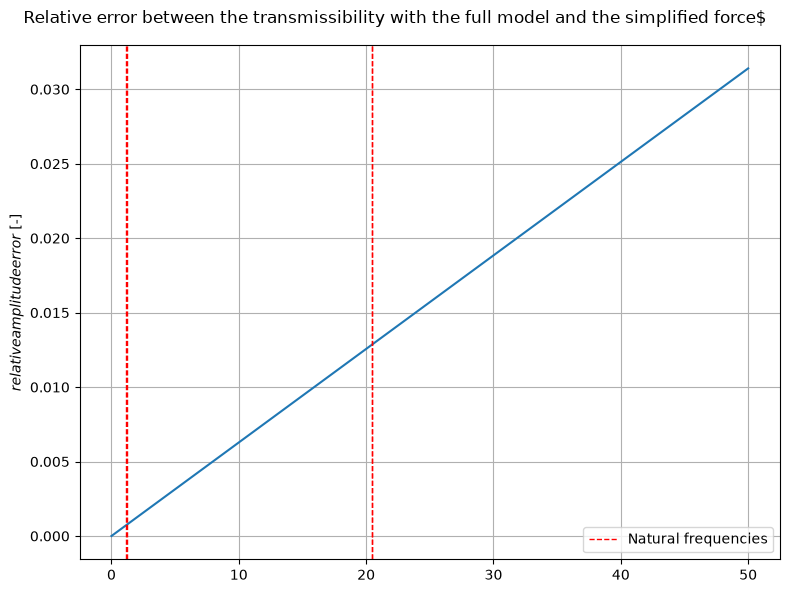

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6), sharex=True)

ax.plot(f, np.abs((q3-q3simp)/q3))
ax.set_ylabel(r"$relative amplitude error$ [-]")
ax.grid(True, which="both")
for i, fn in enumerate(freq_nat):
    ax.axvline(abs(fn), color="r", linestyle="--", linewidth=1,
                  label="Natural frequencies" if i == 0 else None)
ax.legend()


fig.suptitle(r"Relative error between the transmissibility with the full model and the simplified force$")
plt.tight_layout()
plt.show()

Second time we have the same linear curve. With the biggest error at high frequecies. 

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

6. The transmissibilities are used in the theory of vibration isolation. Comment on the shape of these and make a link with the theory in the course. In your opinion, which frequency bands correspond to the amplification and the isolation domain? What role do the wheels play in the isolation?

</div>


### Add your explanation here

## **2.2 Projection in the modal basis**


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Using the simplified force vector, project the equations of motion in the modal domain. Are the equations uncoupled? Why?

</div>


In [13]:
###Lets define a function that will project a matrix in the modal basis
def project_matrix(A:np.ndarray,psi:np.ndarray):
    A_prj = psi.T@A@psi

    return A_prj

In [14]:
M_prj = project_matrix(M, psi)
C_prj = project_matrix(C, psi)
K_prj = project_matrix(K, psi)


###Quid pour le vecteur force ?
#By definition we know that M_prj and K_prj are diagonal, lets verify for C_prj
M_prj_is_diagonal = np.allclose(M_prj, np.diag(np.diag(M_prj)))
K_prj_is_diagonal = np.allclose(K_prj, np.diag(np.diag(K_prj)))
C_prj_is_diagonal = np.allclose(C_prj, np.diag(np.diag(C_prj)))

#Simplified force vector in frequency domain (asuming harmonic excitation)
F_prj_simp = psi.T@(np.array([1, 1, 0, 0])*k)     # X01 = X02 = 1 and b=0

print(f"Is M a diagonal matrix? {M_prj_is_diagonal}")
print(f"Is K diagonal matrix? {K_prj_is_diagonal}")
print(f"Is C diagonal matrix? {C_prj_is_diagonal}")

Is M a diagonal matrix? True
Is K diagonal matrix? False
Is C diagonal matrix? False


en fait c bon mais justifier avec la theorie des perturbations (selon le théorème de Davis-Kahan ou la théorie de Rayleigh-Schrödinger)
il resulte que deux valeurs propres tres proches l'une de l'autre (casi degeneré) entraine un mauvais conditionnement

But the matric C are not diagonal, so our equation are coupled

The verification is not done on the vector why ?????

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. If they are coupled, propose a simplification to decouple the equations of motion, and check its validity by comparing the transmissibility curves $X_{3}/X_{01}$ (assume $X_{01} = X_{02}$ as above), and $q_{3}/X_{01}$ (assume $X_{01} = −X_{02}$ as above) obtained with the full model, and with the decoupled modal projection approach. Is your assumption valid?

</div>


In mechanical vibration there exists several way to compute an approximate diagonal damping matrix:
Rayleigh damping: $C = \alpha K + \beta M$ with $\alpha, \beta \in R$
Modal damping: neglect the non diagonal terms in the modal damping matrix and compute all damping factor $\xi$

We will choose the modal damping approx since we have 2 parameters for 4 DOF.


In [15]:
### test de ma part pour voir la vrai valeur
import scipy.linalg as linalg
def calc_non_conservative_eigenvalues_eigenvectors(M:np.array, C:np.array,K:np.array):
    """
    A function that computes the eigenvalues and eigenvectors
    based on the system parameter by reworking the equations of motion to a generalized eigenvalue problem

    Arguments:
    M, C, K -- system matrices of the MDOF system

    Returns:
    lamb -- The eigenvalues of the eigenvalue problem
    psi -- The eigenvectors of the eigenvalue problem
  
    
    """   
    
    ndof = np.shape(M)[0]
    A  = np.block([[K, np.zeros((ndof,ndof))],[np.zeros((ndof,ndof)), -M]])
    B  = np.block([[C, M],[M, np.zeros((ndof,ndof))]])
    lamb, psi = linalg.eig(A,-B)
    
    # Sorting the results from small to great (by default it is the opposite)
    
    lamb = lamb[::-1]
    psi = psi[:,::-1]

    return lamb[::2], psi[-ndof:,::2]

def calc_xi(lamb):
    """
    A function that computes the damping value from the system pole lambda

    Arguments:
    lamb -- system poles

    Returns:
    xi -- The damping ratio of the pole.
    """


    xi = -lamb.real / abs(lamb)

    return xi



In [16]:
lamb_nc, psi_nc = calc_non_conservative_eigenvalues_eigenvectors(M, C, K)
print(lamb_nc)

i = 1
for lamb_i in lamb_nc:
    print(f'Damping ratio of mode {i}: {calc_xi(lamb_i)*100:.4f}%')
    i+=1

[-0.01685701  -7.23993771j -0.01773899  -7.42761407j
 -3.77647632-128.52945163j -3.77787504-128.53641169j]
Damping ratio of mode 1: 0.2328%
Damping ratio of mode 2: 0.2388%
Damping ratio of mode 3: 2.9370%
Damping ratio of mode 4: 2.9379%


In [17]:
xi_md = [] #vallue of damping ratio with the modal damping simplification


for i in range(len(C)):
    xi_md.append(C_prj[i, i]/(2*M_prj[i, i]*np.sqrt(abs(lamb[i]))))
    print(f'Damping ratio of mode {i}: {xi_md[i]*100:.4f}%')



Damping ratio of mode 0: 0.2328%
Damping ratio of mode 1: 0.2388%
Damping ratio of mode 2: 2.9369%
Damping ratio of mode 3: 2.9379%


In [18]:
#Compute of the modal damping matrix
C_md =  np.diag(np.diag(C_prj))

#Compute the transmissibility X3/X01 and q3/X01 with the modal basis

###First compute function for the response
def Response_based_on_modal_parameters(mu_list: list , w_list: list , xi_list: list,
                                  psi: np.ndarray, force: np.ndarray, omega: np.ndarray):
    
    n_modes = len(mu_list)
    
    # Initialize the FRF as zeros (n_dof x len(omega))
    X = np.zeros((psi.shape[0], len(omega)), dtype=complex)

    # Loop through each mode
    for i in range(n_modes):
      matrix_num = (psi[:, i].T @ force) * psi[:, i]
      matrix_den = mu_list[i] * (w_list[i]**2 - omega**2 + 2j * xi_list[i] * w_list[i] * omega)
      for j, den in enumerate(matrix_den):
            X[:, j] += matrix_num / den

    return X

#Parameters needed:
mu_list =np.diag(M_prj) 
w_list = np.sqrt(np.abs(lamb))

/workspaces/MV2627_Exercises/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


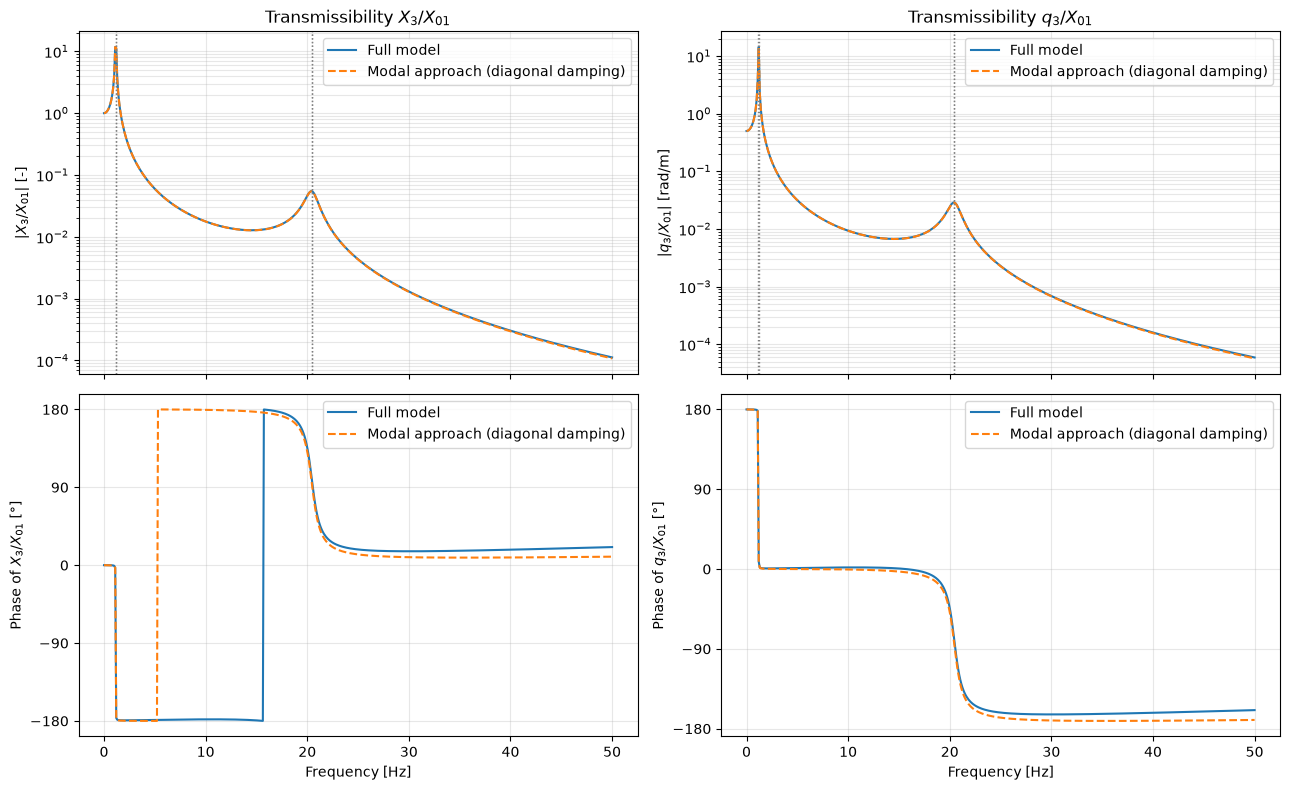

In [19]:
#compute both transmissbility response
X_full1 = Response_based_on_modal_parameters(mu_list, w_list, xi_md, psi, Fsimp, w)
X_full2 = Response_based_on_modal_parameters(mu_list, w_list, xi_md, psi, Fsimp2, w)
X3_md = X_full1[2, :]
q3_md = X_full2[3, :]


fig, ax = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

# ---- Left column: X3 / X01 ----
ax[0, 0].semilogy(f, np.abs(X3),  label='Full model')
ax[0, 0].semilogy(f, np.abs(X3_md), '--', label='Modal approach (diagonal damping)')
ax[0, 0].set_ylabel(r'$|X_3 / X_{01}|$ [-]')
ax[0, 0].set_title(r'Transmissibility $X_3 / X_{01}$')

ax[1, 0].plot(f, np.angle(X3,  deg=True), label='Full model')
ax[1, 0].plot(f, np.angle(X3_md, deg=True), '--', label='Modal approach (diagonal damping)')
ax[1, 0].set_ylabel(r'Phase of $X_3 / X_{01}$ [°]')

# ---- Right column: q3 / X01 ----
ax[0, 1].semilogy(f, np.abs(q3),  label='Full model')
ax[0, 1].semilogy(f, np.abs(q3_md), '--', label='Modal approach (diagonal damping)')
ax[0, 1].set_ylabel(r'$|q_3 / X_{01}|$ [rad/m]')
ax[0, 1].set_title(r'Transmissibility $q_3 / X_{01}$')

ax[1, 1].plot(f, np.angle(q3,  deg=True), label='Full model')
ax[1, 1].plot(f, np.angle(q3_md, deg=True), '--', label='Modal approach (diagonal damping)')
ax[1, 1].set_ylabel(r'Phase of $q_3 / X_{01}$ [°]')

# ---- Common formatting ----
for a in ax.flat:
    a.grid(True, which='both', alpha=0.3)
    a.legend()
for a in ax[0, :]:                      # natural frequencies on amplitude plots
    for fn in freq_nat:
        a.axvline(fn, color='gray', ls=':', lw=1)
for a in ax[1, :]:
    a.set_xlabel('Frequency [Hz]')
    a.set_yticks([-180, -90, 0, 90, 180])

plt.tight_layout()
plt.show()

As we can see on this figure the assumption very good.

# **3. Time Domain Computations**

Assume now a given road profile $w$ and $X_{01} \neq X_{02}$. Using the equations with ***absolute coordinates***, and using the simplified force vector used above:


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Knowing that the frequency of excitation depends on the velocity of the car $v$ and the road profile (in particular the amplitude of its different wavelengths) and using a Fourier transform of the road profile, plot the frequency content of the excitation for three different speeds of the car ($v=5 m/s$, $v= 10 m/s$ and $v=30m/s$).

*N.B.: The road profile is defined in the **w.csv** file (first column: spatial coordinate, second column: road profile amplitude)*

</div>


We know that in the file is define the profile file X(x) = f(x), when the car is moving at constant speed v we have X_01(t) = f(vt) and X_02(t) = f(vt + L). 

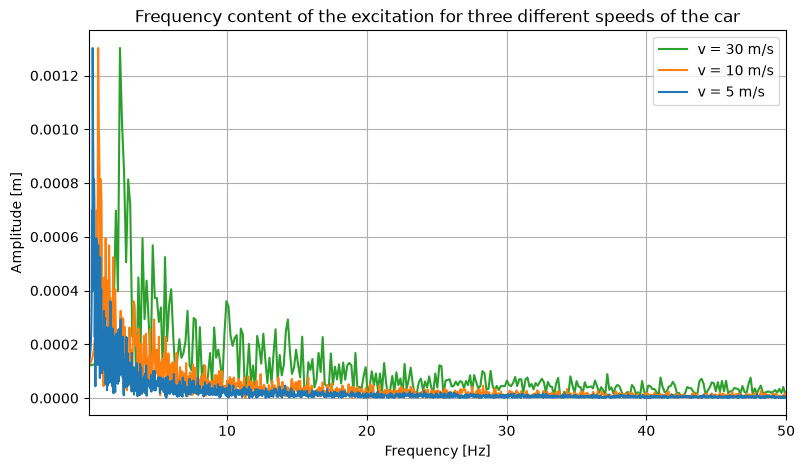

In [20]:
v = np.array([[5], [10], [30]])

road = np.loadtxt('w.csv', delimiter=',')
x, w = road[:,0], road[:,1]

t = x / v

freq  = np.zeros((3, len(w)))         
X_fft = np.zeros((3, len(w)))

for i in range(3):
    freq[i] = np.fft.fftshift(np.fft.fftfreq(len(w), d=t[i, 1]-t[i,0]))
    X_fft[i] = np.fft.fftshift(np.abs(np.fft.fft(w))) / len(w)

# Plot
colors = ['tab:blue', 'tab:orange', 'tab:green']

plt.figure(figsize=(9, 5))
for i in reversed(range(3)):          
    plt.plot(freq[i], X_fft[i], color=colors[i], label=f'v = {v[i,0]} m/s')

plt.xlim(0.1, 50)                    # fréquences positives seulement
plt.title("Frequency content of the excitation for three different speeds of the car")
plt.xlabel('Frequency [Hz]')
plt.ylabel('Amplitude [m]')
plt.grid(True)
plt.legend()
plt.show()



<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. Compute and represent the absolute displacement $X_{3}(t)$ for the three car speeds. Use a convolution between the force vector and the impulse responses, and work with the uncoupled equations in the modal basis. (hint: consider $X_{01}$ and $X_{02}$ as two independent excitation sources, and sum the responses using the property of linearity of the system). Use a relative time ($t/tmax$) in order to plot the curves on the same graph and compare.

*Hint: Use the function `convolve` from `scipy.signal` to compute the convolution as it is faster that numpy*

*Hint: When convolving the force vector with the impulse response, make sure to multiply the result by the time step to get the correct result*
</div>


donc ici on a besoin de deux choses la reponse impulsionnel modale h = 1/wn exp(-Xi wn t) sin(wd t) et de la force dans la base modale F = Psi.T F ou la force est la version ou b=0 donc est égale à k*x_01, k*x_02 et ses deplacement dans le temps mnt on les as avec le profil de la route. Il reste simplement à separer en deux pour après faire une somme de part la linearité. Finalement on reprojette dans les grandeurs du monde réel

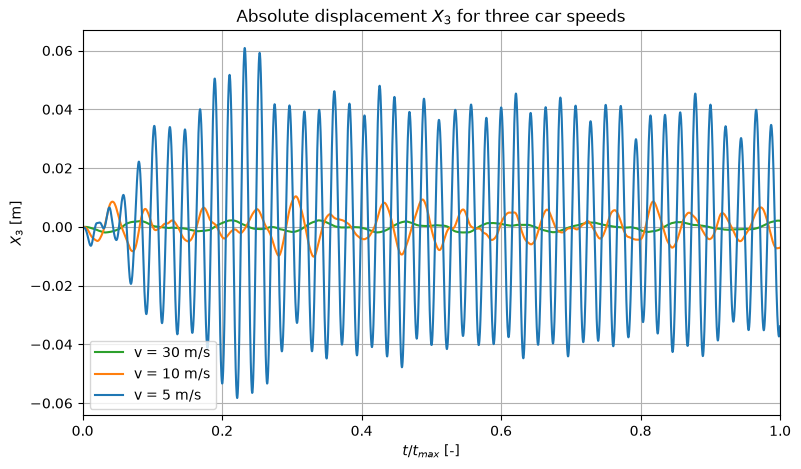

In [ ]:
def impulse_response(m, c, k, t):
    xi  = c/(2*np.sqrt(k*m))
    w_n = np.sqrt(k/m)
    w_d = w_n*np.sqrt(1-xi**2)
    return np.exp(-xi*w_n*t)*np.sin(w_d*t)/(m*w_d)

dx = x[1] - x[0]
nL = int(round(L / dx))        

x_01 = w[:-nL]                 #0 to x_max - L
x_02 = w[nL:]                  #L to x_max
N = len(x_01)                  

F1 = psi.T @ np.outer([1, 0, 0, 0], k*x_01)   
F2 = psi.T @ np.outer([0, 1, 0, 0], k*x_02)   

X3_t = np.zeros((3, N))
for s in range(3):                         
    ts = t[s, :N]
    dt = ts[1] - ts[0]
    z = np.zeros((4, N))
    for j in range(4):               
        h = impulse_response(M_prj[j, j], C_md[j, j], K_prj[j, j], ts) #modal impulse response
        
        z[j] = (signal.convolve(h, F1[j])[:N] + signal.convolve(h, F2[j])[:N])*dt #sum by linearity
    X = psi @ z                            
    X3_t[s] = X[2].real                    

colors = ['tab:blue', 'tab:orange', 'tab:green']

plt.figure(figsize=(9, 5))
for s in reversed(range(3)):                 
    ts = t[s, :N]
    plt.plot(ts / ts[-1], X3_t[s], color=colors[s], label=f'v = {v[s,0]} m/s')

plt.title('Absolute displacement $X_3$ for three car speeds')
plt.xlabel('$t / t_{max}$ [-]')
plt.ylabel('$X_3$ [m]')
plt.xlim(0, 1)
plt.grid(True)
plt.legend()
plt.show()


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

3. Represent the frequency content of the three time domain signals obtained. Compare it to the frequency content of the excitation and comment. What differences do you see for the three different velocities and why ?

</div>

In [ ]:
freqX3  = np.zeros((3, len(N)))         
X3_fft = np.zeros((3, len(N)))

for i in range(3):
    dt = t[i,1]-t[i,0]
    freqX3[i] = np.fft.fftshift(np.fft.fftfreq(len(X3_t[i]), dt))
    X3_fft[i] = np.fft.fftshift(np.abs(np.fft.fft(X3_t[i]))) / len(X3_t[i])



In [24]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

4. Do you notice a difference in the time domain responses in terms of amplitude? Why? Can you make a link with the transmissibility curves computed previously? Can you make a link with the theory covered in the chapter about vibration isolation? At which speed(s) is the car body best isolated?

</div>


### Add your explanation here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

5. Repeat points (2) to (4) for $q_{3}(t)$ at the three different speeds.

</div>


In [25]:
### Add your code here

In [26]:
### Add your code here